# Lab L2-4：把聲音和影像變成「編號」（D2-4）

**需求單 #D2-4**（虛構公司：曜嶼電子，資訊部／客服中心）：通話錄音與產線影像佔滿儲存空間，要用低位元率儲存與串流。
真實客戶錄音是個資，**不能用**；今天用維基百科的公開朗讀錄音（台灣口音國語，CC BY-SA 4.0）代替。

| 步驟 | 做什麼 | 輸出 |
|---|---|---|
| A | EnCodec：同一段錄音壓成 1.5／3／6／12／24 kbps | 音檔、位元率與品質表 |
| B | 自己做一個小 VQ-VAE（Fashion-MNIST），編碼簿大小 16／128／512 | 每張圖幾個 bits、重建誤差 |
| C | 編碼簿用了多少？死碼（dead code） | 使用次數直方圖 |

> 狀態：本筆記本尚未在 Colab T4 實跑（見 `research/lab-runs.md`）。

In [1]:
# 第 1 格：環境
%pip install -q -U transformers soundfile
import torch, time, platform, random, io, urllib.request
import numpy as np
import matplotlib.pyplot as plt
print("torch", torch.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
EPOCHS = 5          # 沒有 GPU：改成 1

torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 5.5 / 15.6 GB


## A. EnCodec：同一段錄音，五種位元率
錄音：維基百科「畢業（演藝界）」條目的朗讀（Wikimedia Commons，CC BY-SA 4.0）。檔案約 54 MB，只取其中 10 秒。

In [2]:
import soundfile as sf
import torchaudio.functional as AF

URL = "https://upload.wikimedia.org/wikipedia/commons/a/ae/Zh-tw-%E7%95%A2%E6%A5%AD%28%E6%BC%94%E8%97%9D%E7%95%8C%29.wav"
LOCAL = "speech_zh_tw.wav"     # 講師可先放到雲端硬碟，改成那個路徑；全班同時下載可能被 Wikimedia 限流（HTTP 429）
import os
if not os.path.exists(LOCAL):
    for attempt in range(3):
        try:
            req = urllib.request.Request(URL, headers={"User-Agent": "gai-course-lab/1.0 (classroom notebook)"})
            open(LOCAL, "wb").write(urllib.request.urlopen(req, timeout=120).read()); break
        except Exception as e:
            print("下載失敗，10 秒後重試：", e); time.sleep(10)
data, sr = sf.read(LOCAL, dtype="float32")
wave = torch.tensor(data if data.ndim == 1 else data.mean(1))          # 轉成單聲道
START, DUR, SR = 5.0, 10.0, 24000
wave = wave[int(START * sr):int((START + DUR) * sr)]
wave = AF.resample(wave, sr, SR)                                        # EnCodec 24 kHz 版本
print(f"原始取樣率 {sr} Hz → {SR} Hz；長度 {len(wave)/SR:.1f} 秒；{len(wave):,} 個數字")
print(f"未壓縮（16 位元 PCM）：{SR * 16 / 1000:.0f} kbps")

原始取樣率 44100 Hz → 24000 Hz；長度 10.0 秒；240,000 個數字
未壓縮（16 位元 PCM）：384 kbps


In [3]:
from transformers import EncodecModel, AutoProcessor
codec = EncodecModel.from_pretrained("facebook/encodec_24khz").to(device).eval()
proc = AutoProcessor.from_pretrained("facebook/encodec_24khz")
inputs = proc(raw_audio=wave.numpy(), sampling_rate=SR, return_tensors="pt")
x_in = inputs["input_values"].to(device)
mask = inputs["padding_mask"].to(device)

def spec_db_error(a, b):
    """頻譜誤差：兩段聲音的頻譜（dB）平均差多少；越低越像。
    不用逐點相減（SNR）：神經網路編碼器不保證波形的相位一樣，聽起來很像，逐點相減卻可能差很多。"""
    win = torch.hann_window(1024)
    A = torch.stft(a, 1024, 256, window=win, return_complex=True).abs()
    B = torch.stft(b, 1024, 256, window=win, return_complex=True).abs()
    db = lambda M: 20 * torch.log10(M.clamp(min=1e-3))          # 低於 −60 dB 的安靜部分不計
    return (db(A) - db(B)).abs().mean().item()

rows, outs = [], {}
for bw in [1.5, 3.0, 6.0, 12.0, 24.0]:
    with torch.no_grad():
        t0 = time.time()
        enc = codec.encode(x_in, mask, bandwidth=bw)
        y = codec.decode(enc.audio_codes, enc.audio_scales, mask)[0]
        sec = time.time() - t0
    codes = enc.audio_codes                              # [chunks, 1, 編碼簿數 n_q, 時間步 T]
    n_q, T = codes.shape[-2], codes.shape[-1]
    bits = n_q * T * np.log2(1024)
    kbps = bits / DUR / 1000
    ref = x_in[0, 0, :y.shape[-1]].cpu(); rec = y[0, 0, :len(ref)].cpu()
    lsd = spec_db_error(ref, rec)
    rows.append((bw, n_q, T, kbps, lsd, sec)); outs[bw] = rec.numpy()
    print(f"{bw:5.1f} kbps 設定 | 編碼簿 {n_q:2d} 本 × {T} 步 | 實際 {kbps:5.2f} kbps | 頻譜誤差 {lsd:5.2f} dB | {sec:.2f} 秒")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/809 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 93.1MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/252 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

  1.5 kbps 設定 | 編碼簿  2 本 × 750 步 | 實際  1.50 kbps | 頻譜誤差  7.80 dB | 0.70 秒
  3.0 kbps 設定 | 編碼簿  4 本 × 750 步 | 實際  3.00 kbps | 頻譜誤差  7.18 dB | 0.12 秒
  6.0 kbps 設定 | 編碼簿  8 本 × 750 步 | 實際  6.00 kbps | 頻譜誤差  6.78 dB | 0.11 秒
 12.0 kbps 設定 | 編碼簿 16 本 × 750 步 | 實際 12.00 kbps | 頻譜誤差  6.49 dB | 0.11 秒
 24.0 kbps 設定 | 編碼簿 32 本 × 750 步 | 實際 24.00 kbps | 頻譜誤差  6.33 dB | 0.11 秒


原始（24 kHz）


EnCodec 1.5 kbps


EnCodec 6.0 kbps


EnCodec 24.0 kbps


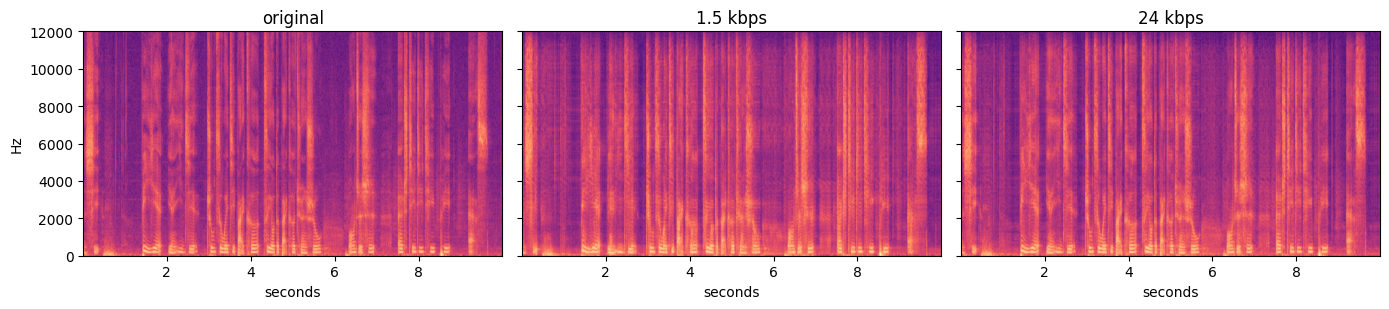

In [4]:
from IPython.display import Audio, display
print("原始（24 kHz）"); display(Audio(x_in[0, 0].cpu().numpy(), rate=SR))
for bw in [1.5, 6.0, 24.0]:
    print(f"EnCodec {bw} kbps"); display(Audio(outs[bw], rate=SR))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for a, (name, sig) in zip(ax, [("original", x_in[0, 0].cpu().numpy()), ("1.5 kbps", outs[1.5]), ("24 kbps", outs[24.0])]):
    a.specgram(sig, NFFT=512, Fs=SR, noverlap=384, cmap="magma"); a.set_title(name); a.set_xlabel("seconds")
ax[0].set_ylabel("Hz"); plt.tight_layout(); plt.savefig("encodec_spectrograms.png", dpi=120); plt.show()

## B. 自己做一個小 VQ-VAE
和 D2-3 的 VAE 同一張主角圖，但瓶頸**對到編碼簿**：每個位置換成「最近的那一格」的編號。

- 編碼器：28×28 → **7×7** 個位置，每個位置一個 16 維向量
- 編碼簿：K 格，每格也是 16 維
- 每張圖 ＝ 49 個編號，每個編號 log2(K) bits

**先別執行**：在投影片「練習：一張圖要幾個 bits？」寫下預測。

In [5]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_ds = datasets.FashionMNIST("data", train=True, download=True, transform=transforms.ToTensor())
test_ds = datasets.FashionMNIST("data", train=False, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
X_test = torch.stack([test_ds[i][0] for i in range(2000)])

class VQVAE(nn.Module):
    def __init__(self, K=128, D=16, beta=0.25):
        super().__init__()
        self.K, self.beta = K, beta
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Conv2d(64, D, 1))
        self.codebook = nn.Embedding(K, D)
        self.codebook.weight.data.uniform_(-1 / K, 1 / K)
        self.dec = nn.Sequential(nn.Conv2d(D, 64, 3, 1, 1), nn.ReLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())

    def quantize(self, z):
        B, D, H, W = z.shape
        flat = z.permute(0, 2, 3, 1).reshape(-1, D)                     # [B·H·W, D]
        idx = torch.cdist(flat, self.codebook.weight).argmin(dim=1)     # [B·H·W]
        z_q = self.codebook(idx).view(B, H, W, D).permute(0, 3, 1, 2)
        return z_q, idx.view(B, H, W)

    def forward(self, x):
        z = self.enc(x)                                                 # [B, D, 7, 7]
        z_q, idx = self.quantize(z)
        codebook_loss = F.mse_loss(z_q, z.detach())                     # 把編碼簿拉向編碼器的輸出
        commit_loss = F.mse_loss(z, z_q.detach())                       # 讓編碼器的輸出別離編碼簿太遠
        z_st = z + (z_q - z).detach()
        x_hat = self.dec(z_st)
        return x_hat, idx, codebook_loss + self.beta * commit_loss

def train_vq(K):
    torch.manual_seed(SEED)
    m = VQVAE(K).to(device); opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    t0 = time.time()
    for epoch in range(EPOCHS):
        m.train()
        for xb, _ in train_loader:
            xb = xb.to(device)
            x_hat, _, vq_loss = m(xb)
            loss = F.mse_loss(x_hat, xb) + vq_loss
            opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        x_hat, idx, _ = m(X_test.to(device))
        mse = F.mse_loss(x_hat, X_test.to(device)).item()
    used = idx.unique().numel()
    bits = idx[0].numel() * np.log2(K)
    print(f"K={K:4d} | 每張 {idx[0].numel()} 個編號 × {np.log2(K):.0f} bits ＝ {bits:.0f} bits | 測試 MSE {mse:.4f} | 用到 {used}/{K} 格 | {time.time()-t0:.0f}s")
    return m, idx.cpu(), mse, bits, used

results = {K: train_vq(K) for K in [16, 128, 512]}
print("原始一張圖：28 × 28 × 8 bits ＝", 28 * 28 * 8, "bits")

K=  16 | 每張 49 個編號 × 4 bits ＝ 196 bits | 測試 MSE 0.0090 | 用到 16/16 格 | 51s
K= 128 | 每張 49 個編號 × 7 bits ＝ 343 bits | 測試 MSE 0.0063 | 用到 110/128 格 | 51s
K= 512 | 每張 49 個編號 × 9 bits ＝ 441 bits | 測試 MSE 0.0060 | 用到 119/512 格 | 51s
原始一張圖：28 × 28 × 8 bits ＝ 6272 bits


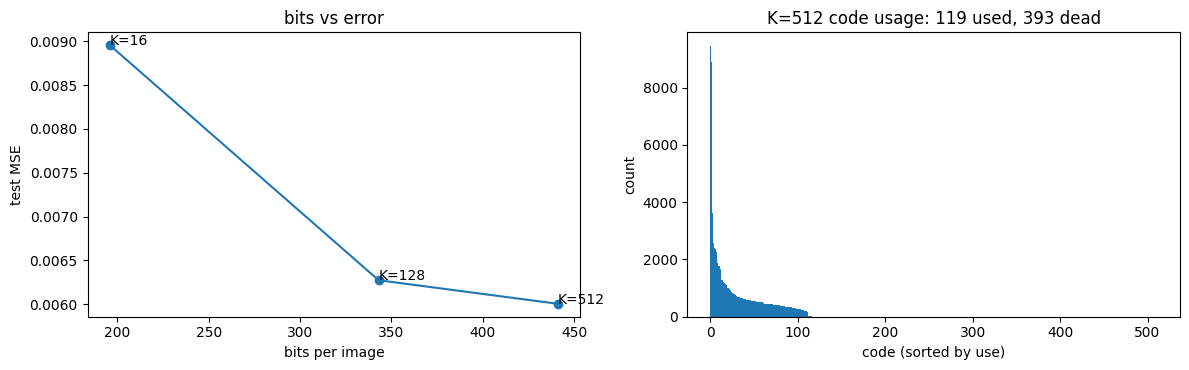

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
Ks = list(results)
ax[0].plot([results[K][3] for K in Ks], [results[K][2] for K in Ks], "o-")
for K in Ks: ax[0].annotate(f"K={K}", (results[K][3], results[K][2]))
ax[0].set_xlabel("bits per image"); ax[0].set_ylabel("test MSE"); ax[0].set_title("bits vs error")
m512, idx512 = results[512][0], results[512][1]
counts = torch.bincount(idx512.flatten(), minlength=512).sort(descending=True).values
ax[1].bar(range(512), counts.numpy(), width=1.0); ax[1].set_xlabel("code (sorted by use)"); ax[1].set_ylabel("count")
ax[1].set_title(f"K=512 code usage: {(counts > 0).sum().item()} used, {(counts == 0).sum().item()} dead")
plt.tight_layout(); plt.savefig("vq_bits_usage.png", dpi=120); plt.show()

## C. 編碼簿用了多少？看編號本身
上一張圖右邊是使用次數直方圖（死碼數寫在標題）。下面把每張圖的 7 × 7 編號畫出來：顏色固定對應 0～511，
但相近的顏色可能是不同編號，**要比的是印出來的數字**。

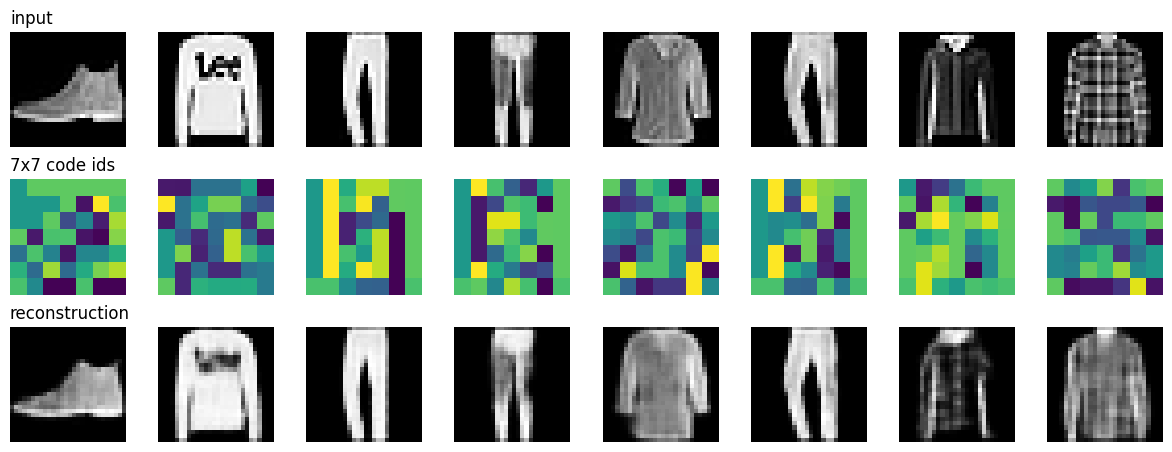

第 0 張（短靴）的 49 個編號：
 [[273 385 385 385 385 385 385]
 [273 273 273 385  25 511 365]
 [273 273 385 119 235  43 444]
 [385  35 365 366  27   6 419]
 [190 366 227  27 235 235 320]
 [328 179 438 179 312 408 452]
 [365 242   3   3 365   3   3]]
第 2 張（褲子）的 49 個編號：
 [[273 511 315 460 460 387 385]
 [273 511 363 506 159 387 385]
 [273 511  48 117 174   3 385]
 [273 511  48 328 460   3 385]
 [273 511 363 274 460   3 385]
 [273 511 315 508 460   3 385]
 [365 365 246 163 159   3 365]]
兩張都用到的編號： [3, 273, 328, 365, 385, 511]


In [7]:
with torch.no_grad():
    x_hat = m512(X_test[:8].to(device))[0].cpu()
fig, ax = plt.subplots(3, 8, figsize=(12, 4.6))
for i in range(8):
    ax[0, i].imshow(X_test[i, 0], cmap="gray"); ax[1, i].imshow(idx512[i], cmap="viridis", vmin=0, vmax=511); ax[2, i].imshow(x_hat[i, 0], cmap="gray")
    for r in range(3): ax[r, i].axis("off")
for r, t in enumerate(["input", "7x7 code ids", "reconstruction"]): ax[r, 0].set_title(t, loc="left")
plt.tight_layout(); plt.savefig("vq_tokens.png", dpi=120); plt.show()
labels = [test_ds.targets[i].item() for i in range(len(idx512))]
shoe, pants = labels.index(9), labels.index(1)          # 9 ＝ 短靴、1 ＝ 褲子（Fashion-MNIST 類別編號）
print(f"第 {shoe} 張（短靴）的 49 個編號：\n", idx512[shoe].numpy())
print(f"第 {pants} 張（褲子）的 49 個編號：\n", idx512[pants].numpy())
common = set(idx512[shoe].flatten().tolist()) & set(idx512[pants].flatten().tolist())
print("兩張都用到的編號：", sorted(common))